# 3D-09 — Des photos au MNT : reconstruire et contrôler une surface

[← Rendu analytique vs radiance field (3D-08)](3D-08-Rendu-Analytique-vs-Radiance-Field-Python.ipynb) | [→ SIG et diffusion 3D (3D-10)](10-SIG-3D-Tiles-Python.ipynb)

Ce carnet introduit la chaîne **images géoréférencées → surface → produit altimétrique** sans prétendre remplacer un logiciel photogrammétrique. Les données sont ici entièrement synthétiques : elles permettent de tester les contrôles et de distinguer hauteur de surface et terrain nu, mais ne démontrent ni reconstruction depuis des photos, ni précision topographique. Une reconstruction réelle demanderait des images recouvrantes, des poses, une calibration et des points de contrôle indépendants.

Objectifs : (1) lire une grille de hauteurs et son emprise ; (2) séparer un modèle numérique de surface (MNS, objets inclus) d'un modèle numérique de terrain (MNT, sol nu) ; (3) mesurer l'effet d'un filtrage/interpolation ; (4) valider le produit sur des points de contrôle non utilisés dans la construction ; (5) exporter et relire un GeoTIFF si Rasterio est installé.

**Limite importante :** lisser ou interpoler ne transforme pas un MNS en MNT. L'identification du sol sous les objets exige une classification fondée sur des observations adaptées. Une texture détaillée n'est pas une preuve de précision altimétrique.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

GRAINE = 2026
rng = np.random.default_rng(GRAINE)
print(f"NumPy {np.__version__} — graine fixée : {GRAINE}")

NumPy 2.4.2 — graine fixée : 2026


## 1. Une scène connue pour éprouver le protocole

On construit une pente douce et une petite butte, puis on ajoute deux objets au-dessus du sol. La surface supérieure est le MNS simulé ; le terrain nu est la vérité de référence du MNT. Le bruit représente une erreur de mesure pédagogique, sans unité ni modèle instrumental réaliste.

Les coordonnées sont des mètres dans un repère local projeté fictif. **Ce repère synthétique n'est pas un CRS officiel** : un vrai projet doit documenter CRS horizontal, datum vertical, unités et transformation utilisée.

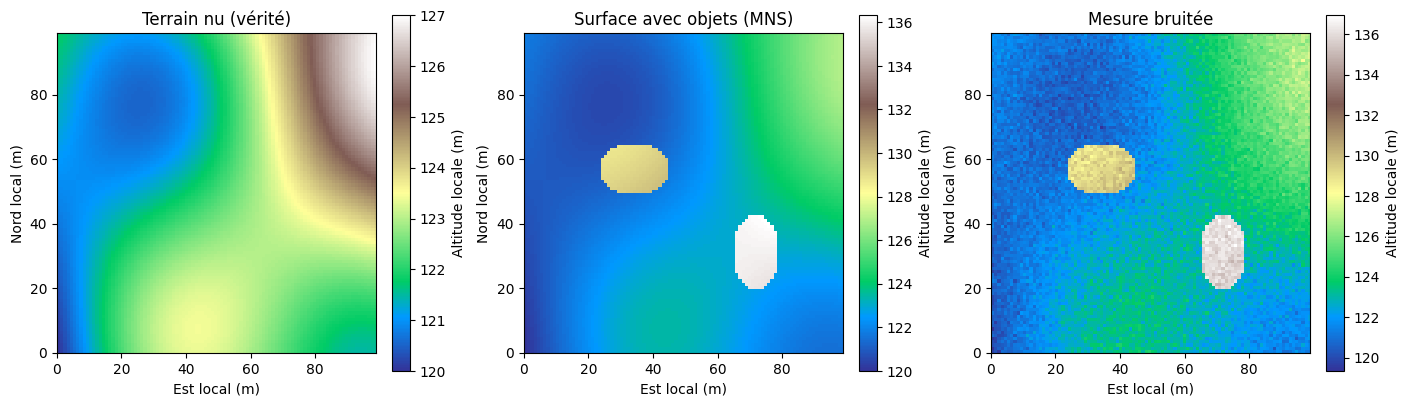

Grille : 100 × 100 cellules ; résolution nominale : 1.0 m


In [2]:
n = 100
x = np.linspace(0.0, 99.0, n)
y = np.linspace(0.0, 99.0, n)
X, Y = np.meshgrid(x, y)
# Terrain de référence : pente douce à laquelle s'ajoute une variation ondulée.
terrain_vrai = 120.0 + 0.035 * X + 0.018 * Y + 2.0 * np.sin(X / 22) * np.cos(Y / 27)
# Deux empreintes elliptiques représentent des objets au-dessus du sol.
objet_a = ((X - 34) ** 2 / 11 ** 2 + (Y - 57) ** 2 / 8 ** 2) < 1
objet_b = ((X - 72) ** 2 / 7 ** 2 + (Y - 31) ** 2 / 12 ** 2) < 1
# Le MNS inclut les objets ; le bruit est ajouté à la mesure simulée.
surface_vraie = terrain_vrai + objet_a * 8.0 + objet_b * 13.0
surface_mesuree = surface_vraie + rng.normal(0, 0.35, size=(n, n))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
# Les trois vues partagent une emprise et une palette pour comparer les altitudes.
for ax, z, titre in zip(axes, [terrain_vrai, surface_vraie, surface_mesuree], ["Terrain nu (vérité)", "Surface avec objets (MNS)", "Mesure bruitée"]):
    im = ax.imshow(z, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="terrain")
    ax.set(title=titre, xlabel="Est local (m)", ylabel="Nord local (m)")
    fig.colorbar(im, ax=ax, label="Altitude locale (m)")
plt.show()
print(f"Grille : {n} × {n} cellules ; résolution nominale : {x[1]-x[0]:.1f} m")

### Lecture du résultat

Les deux bosses sont visibles dans le MNS mais absentes du terrain nu : le maximum de surface ne suffit donc pas à estimer l'altitude du sol. La carte bruitée ajoute des écarts locaux autour de chaque valeur. La résolution affichée est l'espacement de cette grille synthétique, pas une précision certifiée ni la taille de pixel d'une acquisition réelle.

## 2. Une classification pédagogique — et ses hypothèses

Dans cette scène contrôlée, les objets sont connus. On masque leurs cellules et on remplit les trous par interpolation linéaire selon les deux axes. C'est un **témoin de méthode** : dans un vrai nuage, le masque doit provenir d'une classification validée et l'interpolation ne peut pas deviner un terrain que les observations ne contraignent pas.

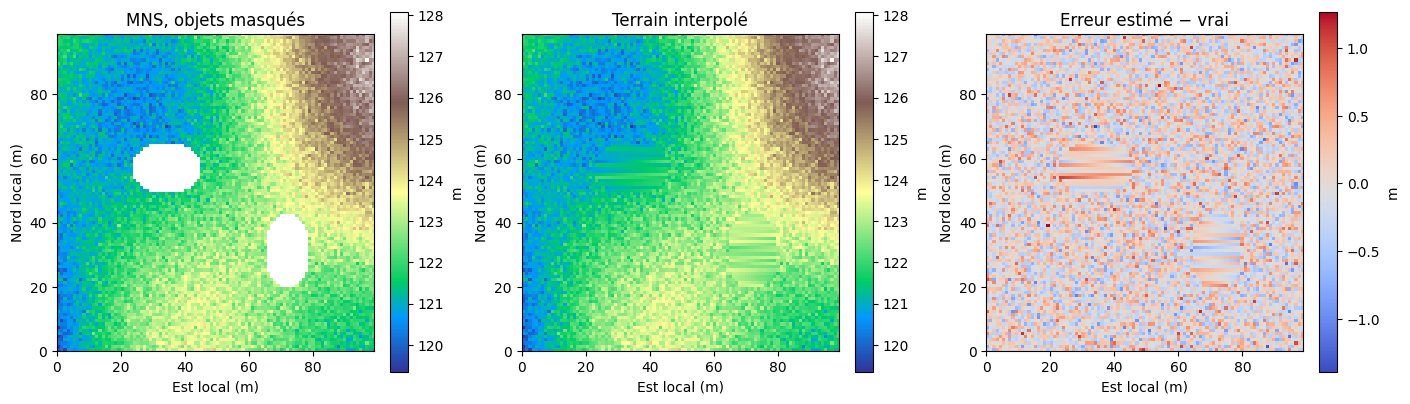

Cellules masquées : 5.3% ; biais moyen : 0.002 m ; RMSE grille : 0.350 m


In [3]:
masque_objets = objet_a | objet_b
surface_masquee = surface_mesuree.copy()
surface_masquee[masque_objets] = np.nan

def interpoler_1d(valeurs):
    """Remplit les NaN d'une ligne par interpolation linéaire des voisins."""
    indices = np.arange(valeurs.size)
    connus = np.isfinite(valeurs)
    if connus.sum() < 2:
        return valeurs.copy()
    resultat = valeurs.copy()
    resultat[~connus] = np.interp(indices[~connus], indices[connus], valeurs[connus])
    return resultat

# Deux passes explicites ; ce choix simple est visible et critiquable.
terrain_estime = np.apply_along_axis(interpoler_1d, 1, surface_masquee)
terrain_estime = np.apply_along_axis(interpoler_1d, 0, terrain_estime)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, z, titre in zip(axes, [surface_masquee, terrain_estime, terrain_estime - terrain_vrai], ["MNS, objets masqués", "Terrain interpolé", "Erreur estimé − vrai"]):
    im = ax.imshow(z, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="coolwarm" if "Erreur" in titre else "terrain")
    ax.set(title=titre, xlabel="Est local (m)", ylabel="Nord local (m)")
    fig.colorbar(im, ax=ax, label="m")
plt.show()
print(f"Cellules masquées : {masque_objets.mean():.1%} ; biais moyen : {(terrain_estime-terrain_vrai).mean():.3f} m ; RMSE grille : {np.sqrt(np.mean((terrain_estime-terrain_vrai)**2)):.3f} m")

### Lecture du résultat

Le masque retire exactement les deux objets connus. L'interpolation donne une surface continue, mais elle peut lisser ou déformer la pente sous les emprises : c'est pourquoi l'erreur est affichée au lieu de présenter le produit comme « vrai ». Les points de contrôle ci-dessous sont tirés hors des objets et ne participent ni au masque ni à l'interpolation ; ils testent le terrain estimé dans des emplacements non utilisés comme contrôle d'entrée.

In [4]:
# Tirage déterministe de contrôles sur terrain nu, distincts des objets.
indices_sol = np.argwhere(~masque_objets)
choix = rng.choice(len(indices_sol), size=40, replace=False)
points_controle = indices_sol[choix]
valeurs_vraies = terrain_vrai[points_controle[:, 0], points_controle[:, 1]]
valeurs_estimees = terrain_estime[points_controle[:, 0], points_controle[:, 1]]
erreurs = valeurs_estimees - valeurs_vraies
# Le biais conserve le signe ; MAE et RMSE résument les amplitudes d'erreur.
rmse_controle = float(np.sqrt(np.mean(erreurs ** 2)))
mae_controle = float(np.mean(np.abs(erreurs)))
print(f"Contrôles indépendants : {len(erreurs)}")
print(f"Biais moyen : {erreurs.mean():.3f} m | MAE : {mae_controle:.3f} m | RMSE : {rmse_controle:.3f} m")
print("Ces métriques mesurent seulement cette scène synthétique et cette interpolation, pas la précision d'une photogrammétrie réelle.")

Contrôles indépendants : 40
Biais moyen : -0.061 m | MAE : 0.293 m | RMSE : 0.355 m
Ces métriques mesurent seulement cette scène synthétique et cette interpolation, pas la précision d'une photogrammétrie réelle.


## 3. Exporter sans perdre le géoréférencement

Un GeoTIFF doit porter une transformation affine, un CRS horizontal connu, les unités et une convention de valeurs nodata. L'exemple ci-dessous utilise volontairement un CRS projeté métrique documenté comme **repère fictif de démonstration** : le code montre le mécanisme d'écriture, mais le fichier ne doit pas être interprété comme une donnée géographique réelle. Rasterio est facultatif ; si absent, on conserve les tableaux NumPy et on n'invente pas de fichier de repli.

In [5]:
from pathlib import Path
import tempfile

try:
    import rasterio
    from rasterio.transform import from_origin
    rasterio_version = rasterio.__version__
except ImportError:
    rasterio = None
    print("Rasterio absent : export GeoTIFF ignoré, aucun fichier substitut n'est créé.")
else:
    print(f"Rasterio {rasterio_version} disponible.")
    # EPSG:32631 sert ici uniquement d'exemple de CRS projeté en mètres ;
    # les coordonnées locales synthétiques ne sont PAS des coordonnées UTM valides.
    print("Avertissement : ne pas attribuer EPSG:32631 à ces coordonnées fictives.")
    print("Dans votre projet, remplacer par le CRS effectivement mesuré avant l'export.")

Rasterio 1.5.2 disponible.
Avertissement : ne pas attribuer EPSG:32631 à ces coordonnées fictives.
Dans votre projet, remplacer par le CRS effectivement mesuré avant l'export.


## 4. Exercices

Les exercices restent exécutables avant complétion. Ils demandent d'expliciter les choix au lieu de masquer l'incertitude : (1) changer le seuil du masque et comparer la RMSE ; (2) retirer un point de contrôle et montrer comment une valeur extrême change le RMSE davantage que la MAE ; (3) proposer un protocole pour obtenir un MNT depuis un nuage de points classifié, en nommant les contrôles qui ne doivent pas servir à régler la classification.

In [6]:
def rmse(reference, estimation):
    """TODO étudiant : calculer la racine de l'erreur quadratique moyenne."""
    return None

# Vérification non bloquante tant que l'exercice n'est pas complété.
resultat_exercice = rmse(np.array([0.0, 1.0]), np.array([0.0, 2.0]))
if resultat_exercice is None:
    print("Exercice à compléter")
else:
    assert np.isclose(resultat_exercice, np.sqrt(0.5))
    print("Exercice réussi")

Exercice à compléter


## À retenir

- Le MNS décrit les objets visibles ; le MNT vise le sol nu. Une surface lissée n'est pas automatiquement un terrain.
- Toute carte doit expliciter CRS, datum vertical, unités, résolution, masque et méthode d'interpolation.
- Les contrôles indépendants évaluent le produit ; ils ne servent pas à le construire ou à régler ses paramètres.
- La texture et la géométrie sont deux informations différentes. Un détail visuel ne certifie pas l'altitude.
- Cette expérience synthétique vérifie du code et du raisonnement seulement. Pour une reconstruction réelle, il faut un jeu autorisé, des observations documentées, un outil photogrammétrique adapté et une validation indépendante.

[→ Carnet suivant : SIG et diffusion progressive 3D (3D-10)](10-SIG-3D-Tiles-Python.ipynb)